# Probabilidad: espacios muestrales, reglas de conteo y modelo clásico

Desarrollo de los ejercicios sobre conceptos básicos, reglas operativas e independencia estadística.
El tratamiento es el del modelo de probabilidad clásico (Laplace), en el cual todos los resultados
simples del experimento son equiprobables y la probabilidad de un evento se obtiene como razón entre
cardinales. Los conteos se resuelven con combinatoria y se verifican en Python (`math`, `itertools`);
los modelos con soporte numerable o continuo se contrastan por simulación Monte Carlo con semilla fija.

## Marco teórico

Sea $\Omega$ el espacio muestral de un experimento aleatorio: el conjunto de resultados posibles,
mutuamente excluyentes y exhaustivos. Un evento $A$ es un subconjunto de $\Omega$. La probabilidad
cumple los axiomas de Kolmogorov:

$$P(A) \ge 0, \qquad P(\Omega) = 1, \qquad P\left(\bigcup_{i} A_i\right) = \sum_{i} P(A_i)$$

si los $A_i$ son mutuamente excluyentes (aditividad). De los axiomas se desprenden las reglas
operativas que se usan en los ejercicios:

$$P(A^c) = 1 - P(A), \qquad P(A \cup B) = P(A) + P(B) - P(A \cap B)$$

$$P(A \cap B) = P(A)\,P(B) \quad \text{si } A \text{ y } B \text{ son independientes}$$

### Modelo clásico

Si $\Omega$ es finito y todos sus elementos son equiprobables:

$$P(A) = \frac{n(A)}{n(\Omega)} = \frac{|A|}{|\Omega|}$$

Supuestos que deben cumplirse para que la fórmula sea válida:

1. $\Omega$ finito y discreto (soportes infinitos o continuos requieren otro formalismo).
2. Equiprobabilidad de los resultados simples de $\Omega$.
3. En muestreos, selección al azar: cada subconjunto de igual cardinalidad tiene la misma
   probabilidad de ser elegido.

### Reglas de conteo

| Concepto | Fórmula | Orden importa | Repetición |
|---|---|---|---|
| Producto | $n_1 \cdot n_2 \cdots n_k$ | - | - |
| Variación (permutación parcial) | $V(n,k) = \dfrac{n!}{(n-k)!}$ | sí | no |
| Variación con repetición | $n^{k}$ | sí | sí |
| Combinación | $C(n,k) = \dfrac{n!}{k!\,(n-k)!}$ | no | no |

El número de arreglos de $k$ elementos tomados de un conjunto de $n$ es $n!/(n-k)!$ cuando el orden
de los elementos interviene en el resultado (claves, recorridos, secuencias de extracciones) y
$C(n,k)$ cuando interviene solo el conjunto (comisiones, grupos de trabajo).

### Distribuciones de referencia

Binomial, $n$ ensayos independientes con probabilidad de éxito $p$:

$$P(X = k) = C(n,k)\, p^{k} (1-p)^{n-k}, \qquad k = 0, \dots, n$$

Geométrica, ensayos independientes con probabilidad $p$; se registra el ensayo en que ocurre el
primer éxito:

$$P(X = k) = (1-p)^{k-1} p, \qquad k = 1, 2, \dots$$

Hipergeométrica, población de $N$ elementos de los cuales $K$ poseen la característica de interés;
se extraen $n$ sin reposición:

$$P(X = k) = \frac{C(K,k)\, C(N-K,\ n-k)}{C(N,n)}$$

La distinción entre binomial e hipergeométrica es directa: la reposición del muestreo garantiza
independencia entre ensayos; sin reposición los ensayos quedan correlacionados y el número de éxitos
sigue una hipergeométrica.

In [1]:
import itertools
import math

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    "figure.figsize": (9, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})

AZUL = "#1f4e79"
GRIS = "#808080"
VERDE = "#2e7d32"
ROJO = "#b03a2e"

print("numpy", np.__version__, "| matplotlib", mpl.__version__)

numpy 2.5.4 | matplotlib 3.11.2


## 1. Espacios muestrales y clasificación del soporte

Clasificación según la cardinalidad de $\Omega$:

| Tipo | Cardinalidad | Tratamiento probabilístico |
|---|---|---|
| Finito | $|\Omega| < \infty$ | modelo clásico, razón de cardinales |
| Infinito numerable | $|\Omega| = \aleph_0$ | soporte discreto $\{1, 2, 3, \dots\}$, masas de probabilidad |
| Infinito no numerable | $|\Omega| = 2^{\aleph_0}$ | soporte continuo (intervalo de $\mathbb{R}$), densidad e integrales |

Un soporte es no numerable cuando los resultados forman un intervalo de $\mathbb{R}$: no existe
correspondencia uno a uno con los naturales, por lo que no puede enumerarse y la probabilidad de un
resultado simple es cero. En ese caso la probabilidad se asigna a intervalos mediante una función de
densidad.

### a) Una extracción, color registrado

$\Omega_a = \{\text{roja},\ \text{blanca}\}$, dos resultados posibles: espacio **finito**. La
composición de la urna fija las probabilidades de cada color, pero no modifica la cardinalidad del
espacio muestral.

In [2]:
urna = ("roja", "blanca")   # colores posibles; el número de bolillas afecta a P, no a Omega
S_a = set(urna)

print("Omega_a =", sorted(S_a))
print("cardinal:", len(S_a), "-> espacio finito")

Omega_a = ['blanca', 'roja']
cardinal: 2 -> espacio finito


### b) Dos extracciones con reposición

$\Omega_b = \{(c_1, c_2) : c_i \in \{\text{roja}, \text{blanca}\}\}$, es decir
$\{$RR, RB, BR, BB$\}$, con cardinal $2^2 = 4$: espacio **finito**. La reposición restaura la
composición de la urna, de modo que ambas extracciones son ensayos independientes con la misma
probabilidad de color; sin reposición el cardinal se reduciría a $2 \cdot 1 = 2$, porque la segunda
extracción dependería del resultado de la primera.

In [3]:
S_b = list(itertools.product(urna, repeat=2))

for i, obs in enumerate(S_b, start=1):
    print(f"{i}. {obs[0]} y {obs[1]}")
print("cardinal:", len(S_b), "-> espacio finito")

1. roja y roja
2. roja y blanca
3. blanca y roja
4. blanca y blanca
cardinal: 4 -> espacio finito


### c) Cuatro lanzamientos de moneda equilibrada, número de caras

El experimento base admite $2^4 = 16$ secuencias equiprobables. Lo registrado es el número de caras
$X$, una variable aleatoria que agrega las secuencias equivalentes:

$$\Omega_c = \{0, 1, 2, 3, 4\}$$

Espacio **finito**, con 5 valores posibles. La moneda equilibrada y la independencia entre lanzamientos
dan $X \sim \text{Binomial}(n=4,\ p=1/2)$:

$$P(X = k) = C(4,k)\left(\frac{1}{2}\right)^{4}$$

In [4]:
secuencias = list(itertools.product("CA", repeat=4))          # C = cara, A = cruz
X = np.array([s.count("C") for s in secuencias])

valores = np.arange(5)
prob = np.array([math.comb(4, k) / 2**4 for k in valores])

print("secuencias posibles:", len(secuencias))
print("valores de X:", sorted(set(X.tolist())))
for k, p in zip(valores, prob):
    print(f"P(X = {k}) = C(4,{k})/16 = {p:.4f}")

secuencias posibles: 16
valores de X: [0, 1, 2, 3, 4]
P(X = 0) = C(4,0)/16 = 0.0625
P(X = 1) = C(4,1)/16 = 0.2500
P(X = 2) = C(4,2)/16 = 0.3750
P(X = 3) = C(4,3)/16 = 0.2500
P(X = 4) = C(4,4)/16 = 0.0625


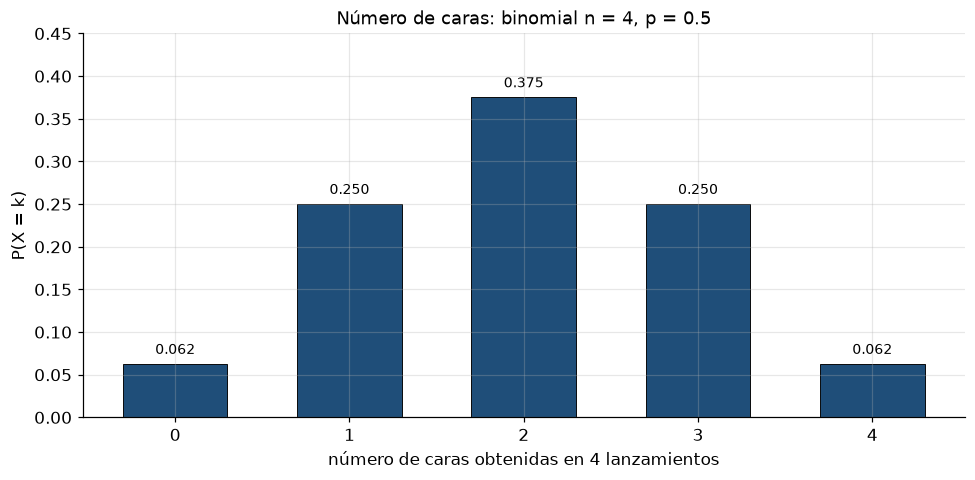

In [5]:
fig, ax = plt.subplots()
ax.bar(valores, prob, width=0.6, color=AZUL, edgecolor="black", linewidth=0.6)
for k, p in zip(valores, prob):
    ax.text(k, p + 0.008, f"{p:.3f}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(valores)
ax.set_xlabel("número de caras obtenidas en 4 lanzamientos")
ax.set_ylabel("P(X = k)")
ax.set_ylim(0, 0.45)
ax.set_title("Número de caras: binomial n = 4, p = 0.5")
plt.tight_layout()
plt.show()

### d) Extracciones con reposición hasta obtener una blanca

Con reposición cada extracción es un ensayo independiente con probabilidad de éxito
$p = P(\text{blanca})$ constante. Se registra el número de extracciones $X$ hasta el primer acierto:

$$\Omega_d = \{1, 2, 3, \dots\}$$

Espacio **infinito numerable**: el soporte es un conjunto discreto sin cota superior; no existe una
última extracción posible. El modelo es la distribución geométrica:

$$P(X = k) = (1-p)^{k-1} p, \qquad k \ge 1$$

La verificación de normalización es la suma de la serie geométrica
$\sum_{k \ge 1} (1-p)^{k-1} p = 1$.

### e) Extracciones sin reposición hasta obtener una blanca, con $n$ bolillas rojas

Sin reposición, con $n$ rojas y una sola blanca, el número de extracciones está acotado: en el peor
de los casos la blanca aparece en la última posición. El espacio muestral es

$$\Omega_e = \{1, 2, \dots, n+1\}$$

Espacio **finito**, con cardinal $n+1$. Además, todos los valores son equiprobables: la bolilla
blanca ocupa indistintamente cualquiera de las $n+1$ posiciones de la extracción aleatoria, de donde

$$P(X = k) = \frac{1}{n+1}, \qquad k = 1, \dots, n+1$$

$X$ es uniforme discreta sobre $\{1, \dots, n+1\}$. Es la contrapartida finita del caso (d): al
eliminarse la reposición desaparece la independencia entre extracciones y el soporte queda acotado,
con evento imposible $\{X > n+1\}$.

caso d, suma de masas k = 1..20: 0.9739 (el resto del soporte sigue)
caso e, suma de masas: 1.0


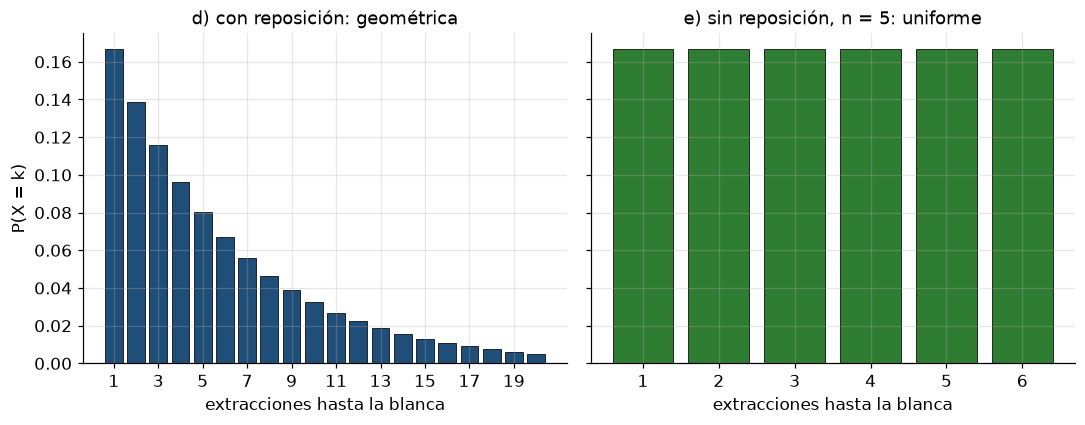

In [6]:
n_rojas = 5
p = 1 / (n_rojas + 1)

# caso d: geométrica con la misma p; el soporte es infinito, se grafican los primeros 20 valores
k_d = np.arange(1, 21)
p_d = (1 - p) ** (k_d - 1) * p

# caso e: uniforme sobre {1, ..., n + 1}
k_e = np.arange(1, n_rojas + 2)
p_e = np.full(k_e.shape, p)

print("caso d, suma de masas k = 1..20:", round(p_d.sum(), 4), "(el resto del soporte sigue)")
print("caso e, suma de masas:", round(p_e.sum(), 4))

fig, axs = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
axs[0].bar(k_d, p_d, color=AZUL, edgecolor="black", linewidth=0.5)
axs[0].set_title("d) con reposición: geométrica")
axs[0].set_xlabel("extracciones hasta la blanca")
axs[0].set_ylabel("P(X = k)")
axs[0].set_xticks(np.arange(1, 21, 2))
axs[1].bar(k_e, p_e, color=VERDE, edgecolor="black", linewidth=0.5)
axs[1].set_title("e) sin reposición, n = 5: uniforme")
axs[1].set_xlabel("extracciones hasta la blanca")
axs[1].set_xticks(k_e)
plt.tight_layout()
plt.show()

In [7]:
# verificación por simulación: posición que ocupa la bolilla blanca en una extracción aleatoria
rng = np.random.default_rng(7)
ensayos = 50_000

posiciones = np.array([rng.permutation(n_rojas + 1).argmax() + 1 for _ in range(ensayos)])
frec = np.bincount(posiciones, minlength=n_rojas + 2)[1:] / ensayos

print("k :", k_e.tolist())
print("exacta :", np.round(p_e, 4))
print("simulada:", np.round(frec, 4))

k : [1, 2, 3, 4, 5, 6]
exacta : [0.1667 0.1667 0.1667 0.1667 0.1667 0.1667]
simulada: [0.166  0.1653 0.17   0.167  0.1673 0.1644]


### f) Tiempo hasta que deje de funcionar un componente electrónico

Se registra una medida física continua, el tiempo de vida en servicio:

$$\Omega_f = [0, \infty)$$

Espacio **infinito no numerable**: un intervalo de $\mathbb{R}$, con cardinalidad igual a la del
continuo. No puede enumerarse ni acotarse por un último valor posible. En la práctica se ajusta una
distribución de densidad, por ejemplo la exponencial de tasa $\lambda$:

$$f(t) = \lambda e^{-\lambda t}, \qquad t \ge 0$$

y las probabilidades se calculan por integral, $P(a \le T \le b) = \int_a^b f(t)\,dt$. La probabilidad
de observar un instante exacto es cero, $P(T = t) = 0$ para todo $t$, por eso el modelo trabaja con
intervalos.

### g) Visita en orden aleatorio de las ciudades A, B, C, D

Se registra el orden en que se visitan las cuatro ciudades: cada permutación de las ciudades es un
resultado posible y todas son equiprobables si el orden se elige al azar. Por regla de conteo,

$$|\Omega_g| = 4! = 24$$

Espacio **finito**. La probabilidad de un recorrido concreto es $1/24$; la de un evento, la razón
entre recorridos favorables y 24.

In [8]:
ciudades = ("A", "B", "C", "D")
S_g = ["".join(p) for p in itertools.permutations(ciudades)]

print("recorridos posibles:", len(S_g), "(4! = 24)")
print("primeros:", S_g[:6])
print("P(recorrido específico) =", round(1 / len(S_g), 4))

recorridos posibles: 24 (4! = 24)
primeros: ['ABCD', 'ABDC', 'ACBD', 'ACDB', 'ADBC', 'ADCB']
P(recorrido específico) = 0.0417


### Resumen de la sección

In [9]:
filas = [
    ("a", "extracción simple, color", 2, "finito"),
    ("b", "dos extracciones con reposición", 4, "finito"),
    ("c", "caras en 4 lanzamientos", 5, "finito"),
    ("d", "extracciones con reposición", "infinito", "infinito numerable"),
    ("e", "extracciones sin reposición, n rojas", "n + 1", "finito"),
    ("f", "tiempo hasta el fallo", "infinito", "infinito no numerable"),
    ("g", "orden de visita de 4 ciudades", 24, "finito"),
]

print(f"{'it':<4}{'experimento':<40}{'cardinal':<12}{'clasificación'}")
print("-" * 78)
for it, desc, card, tipo in filas:
    print(f"{it:<4}{desc:<40}{str(card):<12}{tipo}")

it  experimento                             cardinal    clasificación
------------------------------------------------------------------------------
a   extracción simple, color                2           finito
b   dos extracciones con reposición         4           finito
c   caras en 4 lanzamientos                 5           finito
d   extracciones con reposición             infinito    infinito numerable
e   extracciones sin reposición, n rojas    n + 1       finito
f   tiempo hasta el fallo                   infinito    infinito no numerable
g   orden de visita de 4 ciudades           24          finito


## 2. Tiempo de fragua de un cemento especial

### a) Espacio muestral

La variable registrada es un tiempo de fragua $t$, medida física continua. Los tiempos útiles se
acotan por un mínimo $t_0 > 0$ (por debajo de ese valor el material aún no fragua) y no tienen cota
superior práctica:

$$\Omega = [t_0, \infty) \subset \mathbb{R}$$

No es posible contar los elementos que integran $\Omega$: se trata de un intervalo real, su
cardinalidad es la del continuo ($2^{\aleph_0}$) y cualquier enumeración finita deja infinitos valores
sin cubrir. Corresponde al caso infinito no numerable, con probabilidad definida sobre intervalos a
través de una densidad, y $P(t = c) = 0$ para todo $c$.

### b) Operaciones con los eventos $A$ y $B$

Se definen $A = \{t : 50 \le t \le 100\} = [50, 100]$ y $B = \{t : 70 \le t \le 150\} = [70, 150]$.
Como ambos son intervalos de $\mathbb{R}$, las operaciones de eventos se resuelven con aritmética de
intervalos:

i. $A \cap B$: los tiempos que cumplen ambas condiciones, es decir $\max(50, 70) \le t \le \min(100, 150)$:

$$A \cap B = [70, 100]$$

ii. $A \cup B$: los intervalos se solapan porque $70 \le 100$, por lo que la unión es continua:

$$A \cup B = [50, 150]$$

iii. $A^c \cap B$: los tiempos de $B$ que no pertenecen a $A$. El extremo 100 está incluido en $A$,
quedando fuera del complemento:

$$A^c \cap B = (100, 150]$$

Si se tuvieran probabilidades asignadas, la regla de inclusión y exclusión para el ítem ii sería
$P(A \cup B) = P(A) + P(B) - P(A \cap B)$, donde el término de intersección evita el doble conteo de
los tiempos entre 70 y 100.

In [10]:
def interseccion(a, b):
    """Intersección de intervalos cerrados; devuelve None si no se solapan."""
    lo, hi = max(a[0], b[0]), min(a[1], b[1])
    return (lo, hi) if lo <= hi else None


def union(a, b):
    """Unión de dos intervalos cerrados; devuelve una lista si están disjuntos."""
    if interseccion(a, b) is None:
        return [a, b]
    return (min(a[0], b[0]), max(a[1], b[1]))


def complemento(a, universo=(0, 200)):
    """Complemento de a respecto del universo indicado."""
    trozos = []
    if a[0] > universo[0]:
        trozos.append((universo[0], a[0]))
    if a[1] < universo[1]:
        trozos.append((a[1], universo[1]))
    return trozos


A = (50, 100)
B = (70, 150)

print("A             =", A)
print("B             =", B)
print("A intersección =", interseccion(A, B))
print("A unión        =", union(A, B))
print("Ac             =", complemento(A))
print("Ac intersección B =", interseccion(complemento(A)[-1], B), "(100 abierto: pertenece a A)")

A             = (50, 100)
B             = (70, 150)
A intersección = (70, 100)
A unión        = (50, 150)
Ac             = [(0, 50), (100, 200)]
Ac intersección B = (100, 150) (100 abierto: pertenece a A)


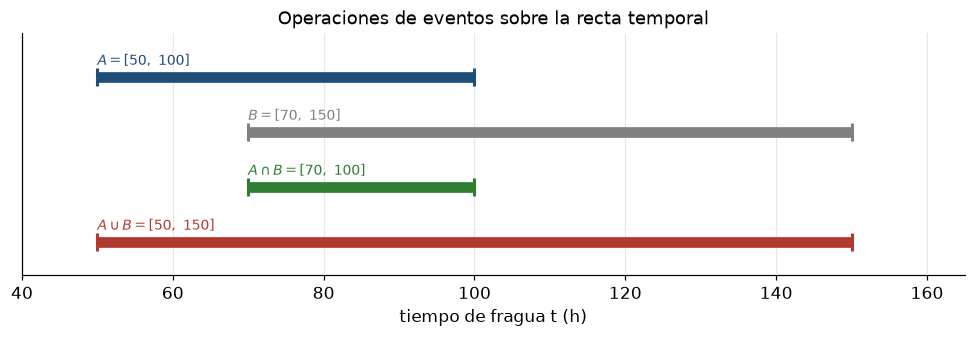

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.2))


def trazo(y, intervalo, color, etiqueta):
    ax.hlines(y, intervalo[0], intervalo[1], color=color, linewidth=7)
    ax.plot(list(intervalo), [y, y], "|", color=color, markersize=12, markeredgewidth=2)
    ax.text(intervalo[0], y + 0.22, etiqueta, fontsize=9, color=color)


trazo(3, A, AZUL, r"$A = [50,\ 100]$")
trazo(2, B, GRIS, r"$B = [70,\ 150]$")
trazo(1, interseccion(A, B), VERDE, r"$A \cap B = [70,\ 100]$")
trazo(0, union(A, B), ROJO, r"$A \cup B = [50,\ 150]$")

ax.set_yticks([])
ax.set_ylim(-0.6, 3.8)
ax.set_xlim(40, 165)
ax.set_xlabel("tiempo de fragua t (h)")
ax.set_title("Operaciones de eventos sobre la recta temporal")
plt.tight_layout()
plt.show()

## 3. Claves de cuatro letras sobre el alfabeto {a, b, c, d}

Alfabeto de $n = 4$ letras, clave de longitud $k = 4$. El número de claves se obtiene por principio
multiplicativo: cada posición de la clave es una etapa de elección.

### a) Ninguna letra se repite

Cada posición admite una letra distinta de las ya utilizadas: $4 \cdot 3 \cdot 2 \cdot 1 = 24$. Es
una permutación completa del alfabeto, $V(4,4) = 4! = 24$ claves.

### b) Las letras pueden repetirse

Cada posición admite las 4 letras sin restricción, de modo que el número de claves es
$4^{4} = 256$. La libertad de repetición multiplica el cardinal por un factor $n$ en cada etapa: para
longitud $k$ el conteo crece como $n^{k}$, mientras que sin repetición decae factorialmente como
$V(n,k)$ y se anula cuando $k > n$.

In [12]:
alfabeto = "abcd"

sin_rep = ["".join(p) for p in itertools.permutations(alfabeto, 4)]
con_rep = ["".join(p) for p in itertools.product(alfabeto, repeat=4)]

print("sin repetición :", len(sin_rep), "| fórmula 4! =", math.factorial(4))
print("con repetición :", len(con_rep), "| fórmula 4^4 =", 4**4)
print("ejemplos sin repetición:", sin_rep[:4])
print("ejemplos con repetición:", con_rep[:4])

sin repetición : 24 | fórmula 4! = 24
con repetición : 256 | fórmula 4^4 = 256
ejemplos sin repetición: ['abcd', 'abdc', 'acbd', 'acdb']
ejemplos con repetición: ['aaaa', 'aaab', 'aaac', 'aaad']


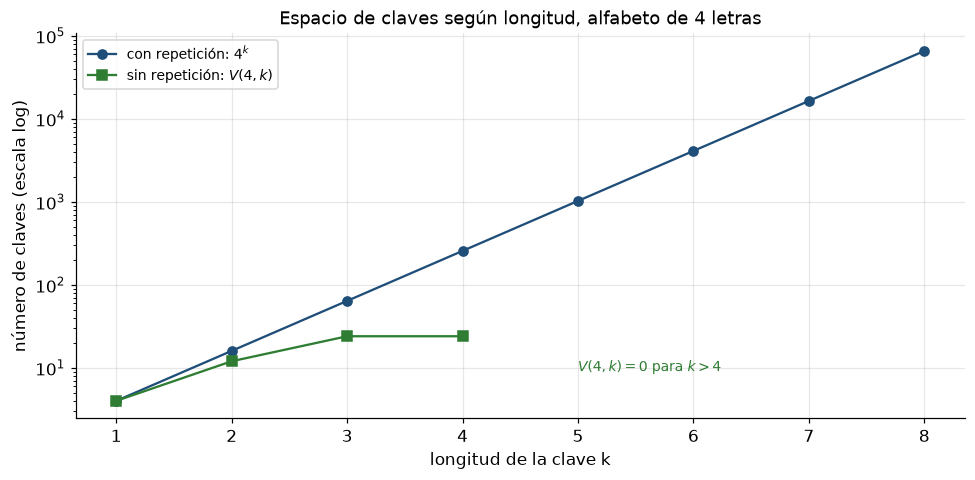

In [13]:
longitudes = np.arange(1, 9)
sin = np.array([math.perm(4, k) for k in longitudes])
con = np.array([4 ** k for k in longitudes])

fig, ax = plt.subplots()
ax.plot(longitudes, con, "o-", color=AZUL, label=r"con repetición: $4^k$")
ax.plot(longitudes[:4], sin[:4], "s-", color=VERDE, label=r"sin repetición: $V(4,k)$")
ax.annotate(r"$V(4,k) = 0$ para $k > 4$", xy=(4.1, 24), xytext=(5.0, 9),
            fontsize=9, color=VERDE, ha="left")
ax.set_yscale("log")
ax.set_xlabel("longitud de la clave k")
ax.set_ylabel("número de claves (escala log)")
ax.set_title("Espacio de claves según longitud, alfabeto de 4 letras")
ax.legend(fontsize=9, loc="upper left")
plt.tight_layout()
plt.show()

## 4. Selección de 3 operarios entre 10

Se elige un subconjunto de 3 operarios de un grupo de 10. El orden en que se nombran no altera la
composición del grupo, por lo que corresponde una combinación sin repetición:

$$C(10,3) = \frac{10!}{3!\,7!} = \frac{10 \cdot 9 \cdot 8}{3 \cdot 2 \cdot 1} = 120$$

Se pueden formar 120 grupos distintos. Supuestos: selección al azar de la totalidad del grupo y
equiprobabilidad de los $C(10,3)$ subconjuntos; si el cargo dentro del grupo definiera roles
distintos, habría que considerar permutaciones en lugar de combinaciones.

In [14]:
n_operarios, n_seleccion = 10, 3

grupos = list(itertools.combinations(range(1, n_operarios + 1), n_seleccion))

print("C(10,3) =", math.comb(n_operarios, n_seleccion))
print("enumerados:", len(grupos))
print("ejemplos:", grupos[:4])

C(10,3) = 120
enumerados: 120
ejemplos: [(1, 2, 3), (1, 2, 4), (1, 2, 5), (1, 2, 6)]


## 5. Grupo de 4 especialistas: 2 de sistemas y 2 de mecánica

El departamento cuenta con 8 especialistas en sistemas y 5 en mecánica. La formación del grupo se
resuelve por etapas: primero se eligen 2 de los 8 sistemas, después 2 de los 5 mecánicos. Las etapas
se desarrollan sobre conjuntos disjuntos, de modo que elegir especialistas de sistemas no modifica la
disponibilidad de los mecánicos y las dos etapas quedan desacopladas. Por el principio multiplicativo
el número de grupos es

$$C(8,2) \cdot C(5,2) = \frac{8!}{2!\,6!} \cdot \frac{5!}{2!\,3!} = 28 \cdot 10 = 280$$

Supuestos: el orden de elección dentro de cada rama no importa (no hay roles diferenciados) y todos
los grupos resultantes son equiprobables.

In [15]:
sistemas, mecanica = 8, 5

parte_sistemas = math.comb(sistemas, 2)
parte_mecanica = math.comb(mecanica, 2)

# verificación por enumeración de las dos etapas
grupos = [(s, m)
          for s in itertools.combinations(range(sistemas), 2)
          for m in itertools.combinations(range(mecanica), 2)]

print(f"C(8,2) = {parte_sistemas}, C(5,2) = {parte_mecanica}")
print("grupos distintos:", parte_sistemas * parte_mecanica)
print("enumerados      :", len(grupos))

C(8,2) = 28, C(5,2) = 10
grupos distintos: 280
enumerados      : 280


## 6. Flota de vehículos: probabilidad de seleccionar uno con problema

Flota de $N = 10$ vehículos de los cuales $K = 4$ presentan algún problema. Se seleccionan $n = 2$ al
azar sin reposición y se registra $X$ = cantidad de vehículos con problema entre los seleccionados.
La selección al azar hace equiprobables los $C(10,2) = 45$ pares posibles.

$X$ es una variable aleatoria hipergeométrica, $X \sim \text{Hipergeométrica}(N=10, K=4, n=2)$:

$$P(X = k) = \frac{C(4,k)\, C(6,\ 2-k)}{C(10,2)}, \qquad k = 0, 1, 2$$

Para el caso pedido, $k = 1$:

$$P(X = 1) = \frac{C(4,1)\, C(6,1)}{45} = \frac{4 \cdot 6}{45} = \frac{24}{45} = \frac{8}{15} \approx 0.5333$$

La extracción sin reposición es el supuesto clave del modelo: los dos vehículos no pueden ser el
mismo, por eso el número de pares favorables es producto de combinaciones y no una binomial con
$n = 2$.

In [16]:
N, K, n = 10, 4, 2

total = math.comb(N, n)
favorables = {k: math.comb(K, k) * math.comb(N - K, n - k) for k in range(3)}
pmf = {k: fav / total for k, fav in favorables.items()}

print(f"total de pares C({N},{n}) = {total}")
for k in favorables:
    print(f"P(X = {k}) = {favorables[k]:2d}/{total} = {pmf[k]:.4f}")
print("suma de probabilidades:", round(sum(pmf.values()), 12))

total de pares C(10,2) = 45
P(X = 0) = 15/45 = 0.3333
P(X = 1) = 24/45 = 0.5333
P(X = 2) =  6/45 = 0.1333
suma de probabilidades: 1.0


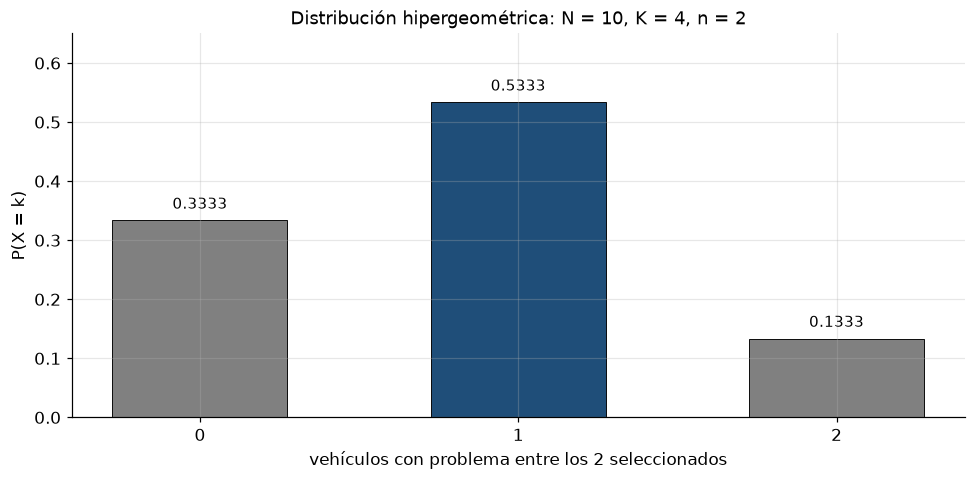

k : [0, 1, 2]
exacta  : [0.3333 0.5333 0.1333]
simulada: [0.3366 0.5309 0.1325]


In [17]:
fig, ax = plt.subplots()
ks = np.array(list(pmf))
vs = np.array(list(pmf.values()))

ax.bar(ks, vs, width=0.55, color=[GRIS, AZUL, GRIS], edgecolor="black", linewidth=0.6)
for k, v in zip(ks, vs):
    ax.text(k, v + 0.02, f"{v:.4f}", ha="center", fontsize=10)
ax.set_xticks(ks)
ax.set_xlabel("vehículos con problema entre los 2 seleccionados")
ax.set_ylabel("P(X = k)")
ax.set_ylim(0, 0.65)
ax.set_title("Distribución hipergeométrica: N = 10, K = 4, n = 2")
plt.tight_layout()
plt.show()

# simulación Monte Carlo del muestreo sin reposición
rng = np.random.default_rng(11)
ensayos = 50_000

muestreo = np.array([rng.choice(N, size=n, replace=False) for _ in range(ensayos)])
con_problema = (muestreo < K).sum(axis=1)
frec = np.bincount(con_problema, minlength=3) / ensayos

print("k :", ks.tolist())
print("exacta  :", np.round(vs, 4))
print("simulada:", np.round(frec, 4))

## Notas de validación

- Los conteos de las secciones 1 a 5 se ajustan al modelo clásico: cardinalidad del evento dividida
  por cardinalidad del espacio muestral, con resultados equiprobables.
- La reposición del muestreo (secciones 1.b y 1.d) habilita el supuesto de independencia entre
  ensayos; sin reposición (secciones 1.e y 6) los ensayos quedan correlacionados y el número de
  aciertos sigue una hipergeométrica, no una binomial.
- Las simulaciones Monte Carlo usan semilla fija para que los resultados sean reproducibles y
  convergen al valor teórico con un error del orden de $1/\sqrt{M}$, siendo $M$ el número de ensayos.
- Comprobaciones realizadas en el notebook: normalización de las masas de probabilidad,
  enumeración directa de los espacios muestrales finitos y de los grupos de las secciones 4 y 5, y
  contrastación teórico-simulada en las secciones 1.e y 6.

Referencias: Ross, S. - Probabilidad y estadística para ingeniería y ciencias. Meyer, P. - Probabilidad
y aplicaciones estadísticas.